In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta. Antes de hacer ningún cálculo numérico, conteste razonando sobre el grafo; después compruébelo.

In [3]:
pregunta_1 = "1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  "
pregunta_2 = "2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) C dura 2 días más; (c) I dura 3 días más. Anote su predicción.  "
pregunta_3 = "3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  "
pregunta_4 = "4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  

2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) C dura 2 días más; (c) I dura 3 días más. Anote su predicción.  

3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  

4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 4       ),
    ('C'     , '---'      , 3       ),
    ('D'     , 'B,C'      , 1       ),
    ('E'     , 'A,D'      , 7       ),
    ('F'     , 'B'        , 5       ),
    ('G'     , 'E,F'      , 1       ),
    ('H'     , 'G'        , 2       ),
    ('I'     , 'E'        , 1       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,4
C,---,3
D,"B,C",1
E,"A,D",7
F,B,5
G,"E,F",1
H,G,2
I,E,1


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  

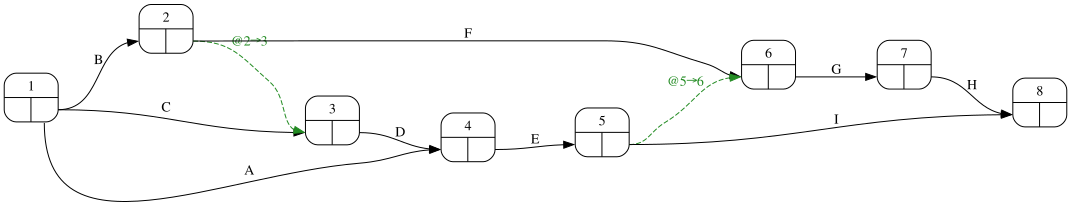

In [8]:
#| fig-cap: "Grafo PERT con numeración de nodos"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

A ojo sólo puede intuirse: las rutas con más actividades o con actividades largas son las candidatas. La forma del grafo no basta; hacen falta las duraciones.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) C dura 2 días más; (c) I dura 3 días más. Anote su predicción.  

Una predicción razonada: el plazo sólo cambia si la actividad está en la ruta más larga, o si el aumento supera la holgura total de la actividad. Sin cálculo sólo es seguro el primer caso si se ha identificado bien la ruta crítica; para los otros dos hace falta saber la holgura.

## Apartado 3

In [10]:
display(Markdown(pregunta_3))

3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  

In [11]:
#| tbl-cap: "Matriz de Zaderenko"
#| label: tbl-zaderenko
proyecto.zaderenko(durations=datos_proyecto['duration'])

,1,2,3,4,5,6,7,8,early
1,,4.0,3.0,7.0,,,,,0.0
2,,,0.0,,,5.0,,,4.0
3,,,,1.0,,,,,4.0
4,,,,,7.0,,,,7.0
5,,,,,,0.0,,1.0,14.0
6,,,,,,,1.0,,14.0
7,,,,,,,,2.0,15.0
8,,,,,,,,,17.0
late,0.0,6.0,6.0,7.0,14.0,14.0,15.0,17.0,


In [12]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,7,0,7,0
B,0,4,2,6,2
C,0,3,3,6,3
D,4,5,6,7,2
E,7,14,7,14,0
F,4,9,9,14,5
G,14,15,14,15,0
H,15,17,15,17,0
I,14,15,16,17,2


## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  

In [14]:
casos = [('H', 2), ('C', 2), ('I', 3)]
filas = []
for act, extra in casos:
    d2 = datos_proyecto['duration'].copy(); d2[act] += extra
    nueva = proyecto.duration(d2)
    filas.append({'actividad': act, 'días de más': extra, 'holgura total': int(calendario.loc[act, 'H_total']),
                  'plazo antes': duracion_proyecto, 'plazo después': nueva,
                  'cambia': 'sí' if nueva > duracion_proyecto else 'no'})
pd.DataFrame(filas).set_index('actividad')

,días de más,holgura total,plazo antes,plazo después,cambia
actividad,,,,,
H,2,0,17,19,sí
C,2,3,17,17,no
I,3,2,17,18,sí


La regla es: el plazo cambia si y sólo si el retraso supera la holgura total de la actividad (para una actividad crítica la holgura es cero y cualquier retraso cuenta). El exceso sobre la holgura es exactamente lo que se alarga el proyecto.